In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ANN model
from sklearn.neural_network import MLPClassifier

# Hyperparameter tuning
from sklearn.model_selection import GridSearchCV

# Model evaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('mobile_price_classification.csv')

In [3]:
df.head()

,battery_power,bluetooth,clock_speed,dual_sim,front_cam,4G,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [5]:
df.shape

(2000, 21)

In [4]:
df.columns

Index(['battery_power', 'bluetooth', 'clock_speed', 'dual_sim', 'front_cam',
       '4G', 'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'primary_camera',
       'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g',
       'touch_screen', 'wifi', 'price_range'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   battery_power   2000 non-null   int64  
 1   bluetooth       2000 non-null   int64  
 2   clock_speed     2000 non-null   float64
 3   dual_sim        2000 non-null   int64  
 4   front_cam       2000 non-null   int64  
 5   4G              2000 non-null   int64  
 6   int_memory      2000 non-null   int64  
 7   m_dep           2000 non-null   float64
 8   mobile_wt       2000 non-null   int64  
 9   n_cores         2000 non-null   int64  
 10  primary_camera  2000 non-null   int64  
 11  px_height       2000 non-null   int64  
 12  px_width        2000 non-null   int64  
 13  ram             2000 non-null   int64  
 14  sc_h            2000 non-null   int64  
 15  sc_w            2000 non-null   int64  
 16  talk_time       2000 non-null   int64  
 17  three_g         2000 non-null   i

In [7]:
df.describe()

,battery_power,bluetooth,clock_speed,dual_sim,front_cam,4G,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


In [8]:
#Check missing values
df.isnull().sum()

,0
battery_power,0
bluetooth,0
clock_speed,0
dual_sim,0
front_cam,0
4G,0
int_memory,0
m_dep,0
mobile_wt,0
n_cores,0


In [9]:
#duplicate
df.duplicated().sum()

np.int64(0)

Exploratory Data Analysis (EDA)

In [10]:
#Check target variable distribution
df['price_range'].value_counts()

,count
price_range,
1,500
2,500
3,500
0,500


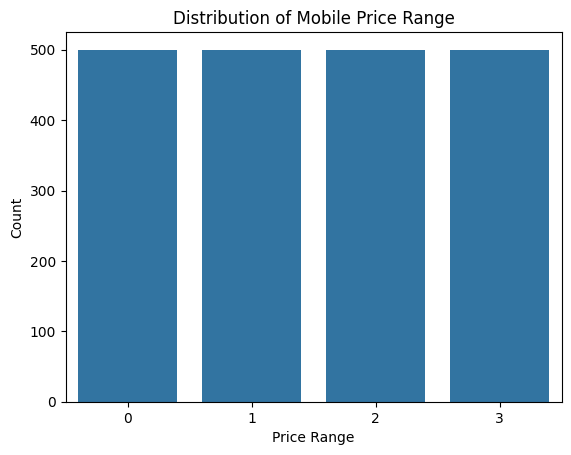

In [11]:
sns.countplot(x='price_range', data=df)

plt.title('Distribution of Mobile Price Range')
plt.xlabel('Price Range')
plt.ylabel('Count')

plt.show()

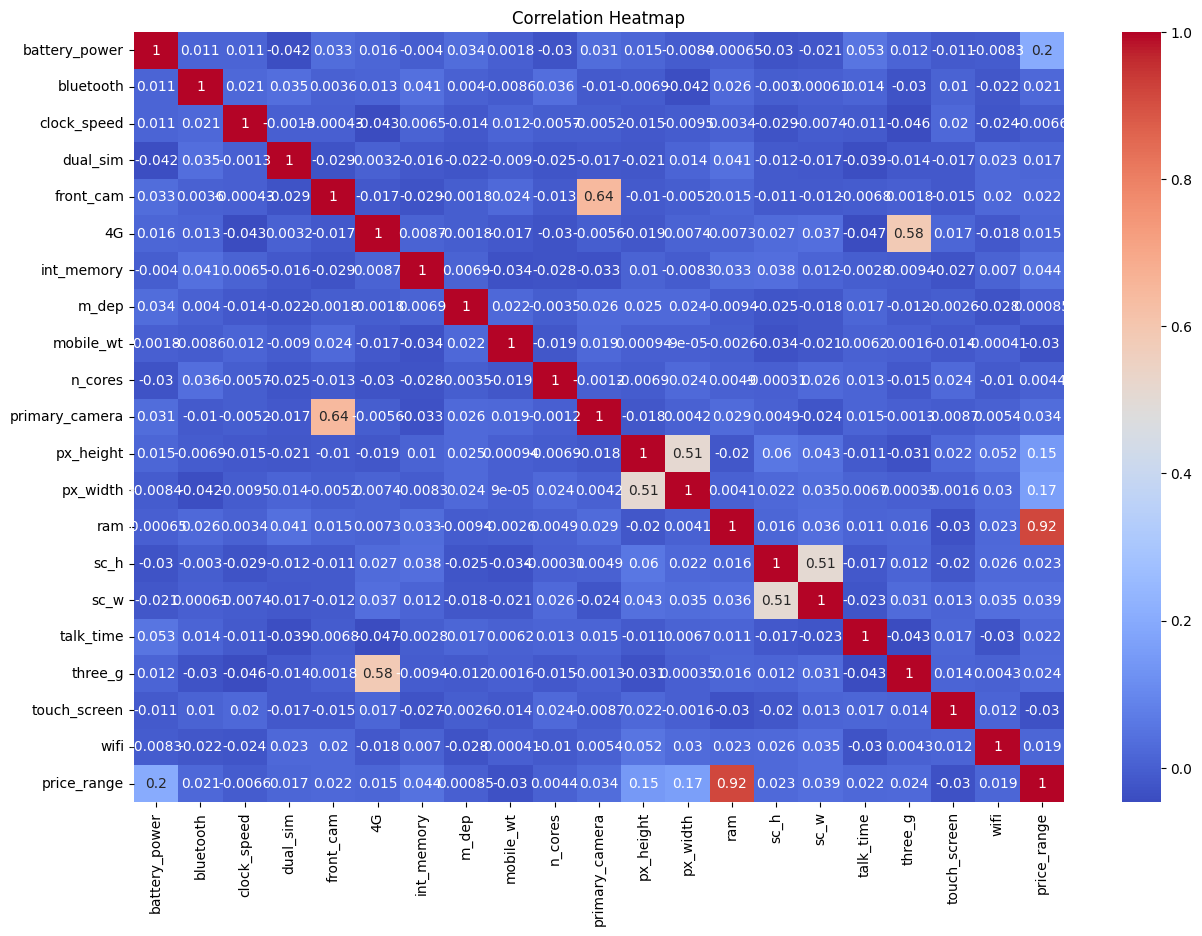

In [12]:
#Correlation heatmap
plt.figure(figsize=(15, 10))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

plt.title('Correlation Heatmap')

plt.show()

In [15]:
#Separate Independent and Dependent Variables
X = df.drop('price_range', axis=1)
y = df['price_range']

In [16]:
print("X shape:", X.shape)

print("y shape:", y.shape)

X shape: (2000, 20)
y shape: (2000,)


In [17]:
#Split the Dataset into Training and Testing Data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [18]:
print("X_train:", X_train.shape)

print("X_test:", X_test.shape)

print("y_train:", y_train.shape)

print("y_test:", y_test.shape)

X_train: (1600, 20)
X_test: (400, 20)
y_train: (1600,)
y_test: (400,)


In [21]:
#Feature Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)
print(X_train_scaled[:5])

[[ 1.38919326  1.011314   -1.25918898  0.98634324  1.30925256 -1.03693152
   1.58482903 -0.70458975 -1.25033529 -1.5516371   0.35023908 -0.79884868
  -1.28564151 -0.36302366 -0.78128983 -0.17762722 -0.89664506 -1.78870765
  -1.00878862 -1.02532046]
 [ 0.07840603  1.011314   -1.25918898 -1.01384584  1.77045998 -1.03693152
  -0.00345726 -1.39684863 -0.76837395  1.0731587   0.84454887  1.58230174
   1.63767503 -1.54789561  0.64708236  1.87520744  0.56094407 -1.78870765
  -1.00878862  0.97530483]
 [-1.02457347 -0.98881258  1.18747125  0.98634324 -0.0743697   0.96438384
   1.36575506  1.37218691 -1.39208862  1.51062466  0.35023908 -1.36150237
  -0.19930538  1.69898521 -0.06710374  0.506651   -0.89664506  0.55906285
   0.99128795  0.97530483]
 [ 0.38669222 -0.98881258 -1.25918898  0.98634324 -0.53557712  0.96438384
   0.10607972  1.02605747 -1.19363396 -0.67670517 -0.80315042  0.83284703
   0.27858927  1.64923164 -0.78128983  0.506651   -1.62543963  0.55906285
  -1.00878862  0.97530483]
 [-0

In [22]:
#Build the Artificial Neural Network (ANN) Model
ann_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)

In [23]:
#Train the ANN Model
ann_model.fit(X_train_scaled, y_train)

MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)

In [26]:
#Predict
y_pred = ann_model.predict(X_test_scaled)
print(y_pred)

[3 2 0 2 3 2 0 0 1 0 3 0 0 1 3 3 2 1 1 3 1 0 3 2 2 1 1 0 2 1 1 2 0 2 2 3 0
 3 1 0 2 0 0 2 3 0 3 3 2 1 0 3 0 2 0 3 3 0 2 1 1 2 3 1 0 0 0 1 3 3 3 2 1 1
 2 1 2 2 2 3 3 2 2 0 0 1 0 0 0 0 0 2 2 3 0 3 0 0 2 2 3 1 1 0 3 3 2 2 1 1 0
 2 3 1 3 2 2 2 2 2 2 0 3 0 2 3 2 1 2 3 3 0 0 1 3 1 1 3 2 3 3 3 2 1 3 2 1 2
 0 1 3 0 1 0 3 3 3 3 0 2 1 0 0 3 1 1 3 2 3 0 1 1 1 3 2 1 1 3 0 3 2 2 2 3 0
 2 0 1 1 1 0 2 1 2 3 0 2 3 1 1 1 2 1 3 0 0 3 0 2 2 0 3 2 0 0 3 1 2 3 3 0 3
 3 2 2 1 1 2 0 1 0 2 0 0 0 0 0 2 2 2 2 3 0 1 3 2 2 3 3 2 1 0 3 3 1 3 2 1 1
 2 2 2 2 1 0 0 3 1 2 3 3 0 0 0 1 3 2 2 3 1 3 2 2 1 1 0 1 1 1 3 1 0 3 1 1 1
 0 1 1 1 1 3 0 3 2 3 1 3 1 2 0 0 2 3 3 2 3 1 0 2 0 2 3 3 0 0 3 1 0 1 1 0 0
 0 0 0 3 1 3 0 1 2 3 2 3 1 2 1 2 3 3 0 2 2 1 0 0 1 2 2 3 1 1 0 3 3 3 1 2 1
 1 0 0 2 1 0 0 0 3 1 1 2 0 3 0 3 1 3 3 2 0 1 1 1 0 1 2 0 2 1]


In [27]:
comparison = pd.DataFrame({
    'Actual Price Range': y_test.values,
    'Predicted Price Range': y_pred
})

comparison.head(10)

,Actual Price Range,Predicted Price Range
0,3,3
1,1,2
2,0,0
3,2,2
4,3,3
5,2,2
6,0,0
7,0,0
8,1,1
9,0,0


In [28]:
#Evaluate the ANN Model
accuracy = accuracy_score(y_test, y_pred)

print("ANN Model Accuracy:", accuracy)

ANN Model Accuracy: 0.92


In [29]:
print("ANN Model Accuracy:", accuracy * 100, "%")

ANN Model Accuracy: 92.0 %


In [30]:
#classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.95      0.95       100
           1       0.89      0.89      0.89       100
           2       0.90      0.89      0.89       100
           3       0.95      0.95      0.95       100

    accuracy                           0.92       400
   macro avg       0.92      0.92      0.92       400
weighted avg       0.92      0.92      0.92       400



In [31]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[95  5  0  0]
 [ 6 89  5  0]
 [ 0  6 89  5]
 [ 0  0  5 95]]


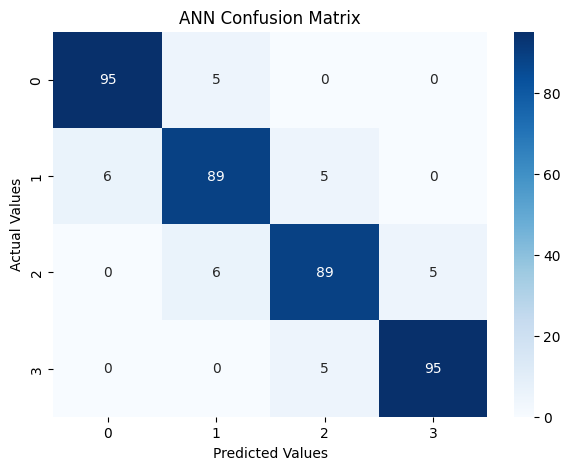

In [32]:
plt.figure(figsize=(7, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('ANN Confusion Matrix')

plt.xlabel('Predicted Values')

plt.ylabel('Actual Values')

plt.show()

In [33]:
#Hyperparameter Tuning Using GridSearchCV
param_grid = {
    'hidden_layer_sizes': [(32,), (64,), (64, 32)],

    'activation': ['relu', 'tanh'],

    'alpha': [0.0001, 0.001],

    'learning_rate_init': [0.001, 0.01]
}

In [35]:
#GRID SEARCH CV
grid_search = GridSearchCV(
    estimator=MLPClassifier(
        solver='adam',
        max_iter=500,
        random_state=42
    ),

    param_grid=param_grid,

    cv=5,

    scoring='accuracy',

    n_jobs=-1,

    verbose=1
)
grid_search.fit(X_train_scaled, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


GridSearchCV(cv=5, estimator=MLPClassifier(max_iter=500, random_state=42),
             n_jobs=-1,
             param_grid={'activation': ['relu', 'tanh'],
                         'alpha': [0.0001, 0.001],
                         'hidden_layer_sizes': [(32,), (64,), (64, 32)],
                         'learning_rate_init': [0.001, 0.01]},
             scoring='accuracy', verbose=1)

In [36]:
print("Best Cross Validation Accuracy:")

print(grid_search.best_score_)

Best Cross Validation Accuracy:
0.9475000000000001


In [37]:
#BEST ANN
best_ann_model = grid_search.best_estimator_

In [38]:
#Evaluate the Tuned ANN Model
y_pred_tuned = best_ann_model.predict(X_test_scaled)

In [39]:
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

print("Tuned ANN Accuracy:", tuned_accuracy)

print("Tuned ANN Accuracy (%):", tuned_accuracy * 100)

Tuned ANN Accuracy: 0.965
Tuned ANN Accuracy (%): 96.5


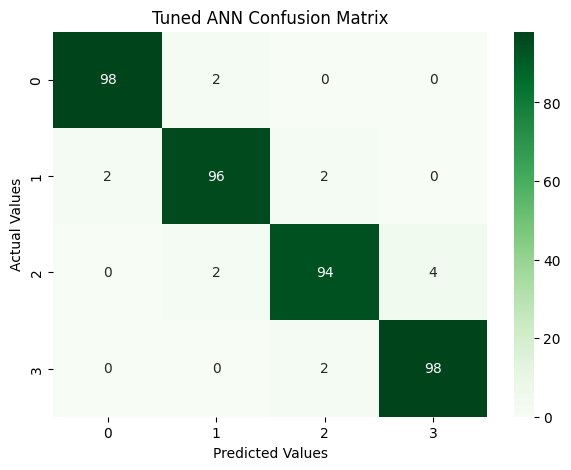

In [40]:
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(7, 5))

sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Greens')

plt.title('Tuned ANN Confusion Matrix')

plt.xlabel('Predicted Values')

plt.ylabel('Actual Values')

plt.show()

In [41]:
#COMPARING
results = pd.DataFrame({
    'Model': ['Original ANN', 'Tuned ANN'],

    'Accuracy': [accuracy, tuned_accuracy]
})

results

,Model,Accuracy
0,Original ANN,0.920
1,Tuned ANN,0.965


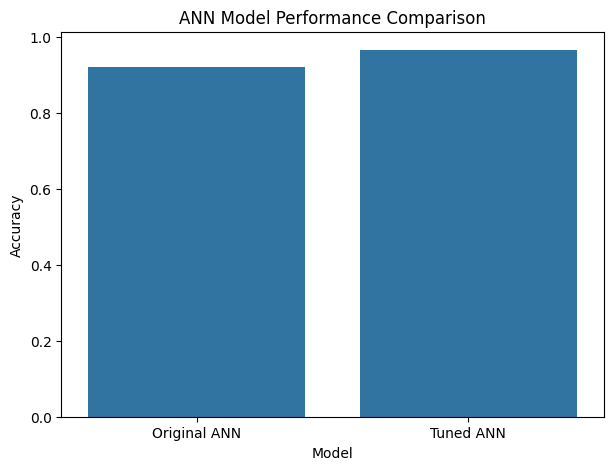

In [42]:
plt.figure(figsize=(7, 5))

sns.barplot(x='Model', y='Accuracy', data=results)

plt.title('ANN Model Performance Comparison')

plt.ylabel('Accuracy')

plt.show()

The dataset was loaded and explored. Data cleaning was performed, and the independent and dependent variables were separated. The dataset was divided into training and testing sets, followed by feature scaling using StandardScaler.

An ANN classification model was developed using MLPClassifier and evaluated using accuracy score, classification report, and confusion matrix.

Hyperparameter tuning was performed using GridSearchCV to identify the best combination of ANN parameters. Finally, the original ANN model and tuned ANN model were compared based on their accuracy.

The model can classify mobile phones into four different price categories based on their features.